# Comparing Models

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import netCDF4
from pathlib import Path
from datetime import datetime
import json
import torch

In [2]:
from helpers.data_funcs import make_index #need to restart kernel to get these updated!!
from helpers.data_funcs import IcepackDataset
from helpers.data_funcs import read_mod_file
from helpers.models_funcs import train
from helpers.models_funcs import validate
from helpers.models_funcs import evaluate

In [3]:
from helpers.network_architectures import *
import torch.nn as nn
from torch.utils.data import Subset, DataLoader
from tabulate import tabulate

## Config

In [4]:
RUN_NAME = "ksno16"
SPLIT_NAME = "split1_enthalpy"
EXPERIMENT_NAME_list = ["CNN_MSE_default"]#,"CNN_MSE_default_long2" ]

### Loading Data

In [5]:
RUN_DIR = Path(f"/projects/dagr5998/cleaned_data/01icepack_array_output/{RUN_NAME}_daily")
SPLIT_DIR = Path(f"/projects/dagr5998/cleaned_data/02icepack_split_output/{RUN_NAME}_split/{SPLIT_NAME}")

In [6]:
X = np.load(RUN_DIR / "X.npy") # input array
Y = np.load(RUN_DIR / "Y.npy") # output array
sets = np.load(RUN_DIR / "sets.npy") # changed parameter set index
parameterizations = np.load(RUN_DIR / "parameterizations.npy") # changed parameterizations
locations = np.load(RUN_DIR/"locations.npy") 

In [7]:
val_index = np.load (SPLIT_DIR/"val_index.npy")
val_ind = np.load (SPLIT_DIR/"val_ind.npy")

In [8]:
with open(RUN_DIR / 'config.json') as f:
    config = json.load(f)
with open(SPLIT_DIR / 'split_config.json') as f:
    split_config = json.load(f)
var_ind_list = split_config["var_ind_list"]
Xt = torch.from_numpy(X[:, :, var_ind_list].copy())
Yt = torch.from_numpy(Y)
training_vars = split_config["training_vars"]
input_window = split_config["input_window_timesteps"]
mu,sd = np.load(SPLIT_DIR / 'mu.npy'), np.load (SPLIT_DIR/'sd.npy')
mu,sd = torch.from_numpy(mu), torch.from_numpy(sd)
val_ds = IcepackDataset(Xt, Yt, val_index, input_window, mu,sd)

In [9]:
train_ind = np.load (SPLIT_DIR/"train_ind.npy")
baseline = Yt[list(train_ind)].mean(dim = 0)
#baseline

### Loading Models

In [10]:
def rebuild_net(train_config, EXPERIMENT_DIR):
    model = blank_model(train_config["model_choice"],train_config["input_window"], len(train_config["training_vars"]), **train_config["model_options"] )
    state_dict = torch.load(EXPERIMENT_DIR /"model.pth")
    model.load_state_dict(state_dict)
    return(model)


def load_experiment(name):
    EXPERIMENT_DIR = Path(f"/projects/dagr5998/cleaned_data/03icepack_experiment_output/{RUN_NAME}/{SPLIT_NAME}/{name}")
    with open(EXPERIMENT_DIR / 'train_config.json') as f:
        train_config = json.load(f)
    y_mu, y_sd = torch.tensor(train_config["y_mu"]), torch.tensor(train_config["y_sd"])
    model = rebuild_net(train_config, EXPERIMENT_DIR)
    return model, train_config


def ice_days(index, window =365, cutoff = 0.15):
    # 0.15 from DAlooza talk, takes val_index returns the number of days with ice above threshold
    aicen_idx = [split_config["training_vars"].index(f"aicen_ncat{i}") for i in range(1,6)]
    days_list = []
    for run,start in index:
        days_list.append(int(sum(Xt[run,start:start+window,aicen_idx].sum(1)>0.15)))
    return np.array(days_list)

In [11]:
results = {}
truth_val = Yt[val_index[:,0]]
for experiment in EXPERIMENT_NAME_list:
    print(experiment)
    modeli, config_i = load_experiment(experiment)
    
    
    assert(config_i["training_vars"] == training_vars)
    assert(input_window == config_i["input_window"])
    assert(config_i["run_DIR"]==str(RUN_DIR))
    assert(config_i["split_dir"]==str(SPLIT_DIR))
    
    loss_dict = LOSS_CHOICES[config_i["loss_choice"]]
    y_mu, y_sd = torch.tensor(config_i["y_mu"]),torch.tensor(config_i["y_sd"])
    guesses_val =  evaluate(modeli,val_ds,y_mu,y_sd,loss_dict["eval_method"] )
    rmse = torch.sqrt(((guesses_val - truth_val)**2).mean())
    
    
    results[experiment] = {"guesses":guesses_val, "train_config" : config_i, "model":modeli}

CNN_MSE_default


## Comparing Models

In [12]:
guesses_baseline = torch.full(truth_val.size(), float(baseline))

In [13]:
comp_table = [["Experiment", "RMSE", "MAE", "Best Epoch"],
            ["Baseline", round(float(torch.sqrt(((guesses_baseline - truth_val)**2).mean())),4), round(float(torch.abs(((guesses_baseline - truth_val)).mean())),4)]]
for experiment, result in results.items():
    rmse = torch.sqrt(((result["guesses"] - truth_val)**2).mean())
    #rmse = config_i["valrmse"]
    mae = (torch.abs(result["guesses"] - truth_val)).mean()
    best_epoch = result["train_config"]["best_epoch"]
    comp_table.append([experiment, round(float(rmse),4), round(float(mae),4), best_epoch])
print(tabulate(comp_table))
                

---------------  ------  ------  ----------
Experiment       RMSE    MAE     Best Epoch
Baseline         0.0726  0.0142
CNN_MSE_default  0.0287  0.016   953
---------------  ------  ------  ----------


In [14]:
#result.items()

### Plots

CNN_MSE_default: epochs 300-600 mean 0.0939   last 250 mean 0.0894


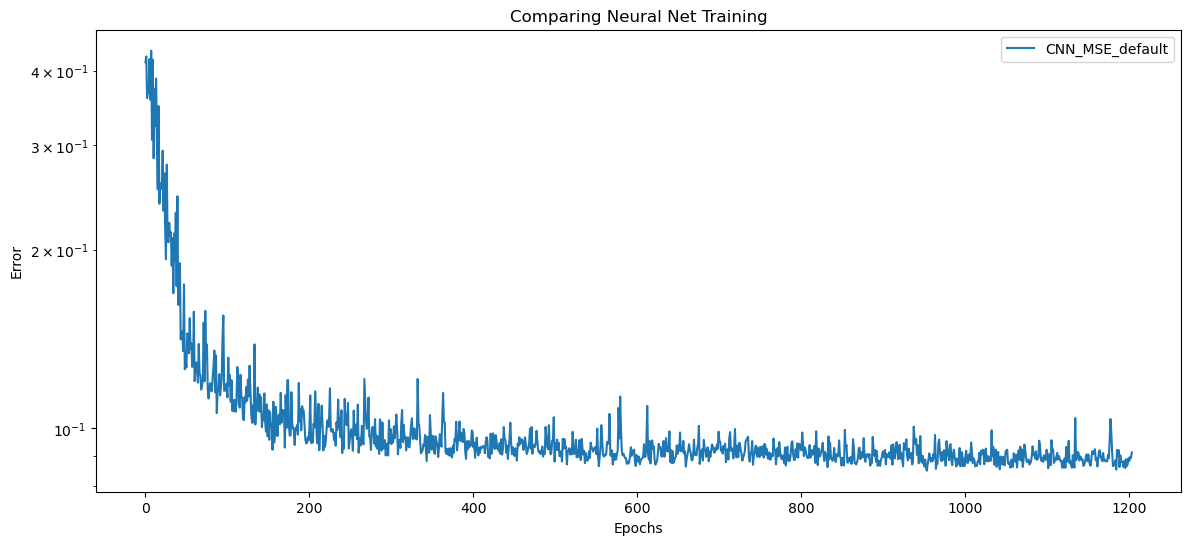

In [15]:
plt.figure(figsize=(14, 6)) 
for experiment, result in results.items():
    EXPERIMENT_DIR = Path(f"/projects/dagr5998/cleaned_data/03icepack_experiment_output/{RUN_NAME}/{SPLIT_NAME}/{experiment}")
    val_history = np.load(EXPERIMENT_DIR / "validation_error_history.npy")
    plt.semilogy(val_history, label = experiment)
    print(f"{experiment}: epochs 300-600 mean {val_history[300:600].mean():.4f}   last 250 mean {val_history[-250:].mean():.4f}")

plt.xlabel("Epochs")
plt.ylabel("Error")
plt.legend()
plt.title("Comparing Neural Net Training")
plt.show()

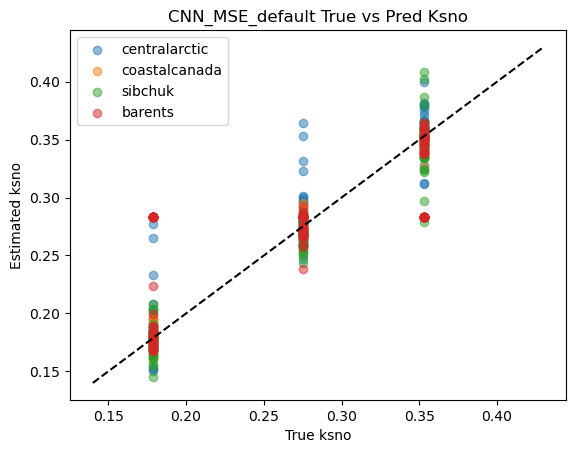

In [16]:
loc_val = locations[val_index[:, 0]]
loc_list = ["centralarctic", "coastalcanada", "sibchuk", "barents"]
loc_index = [0,1,2,3]
loc_list = [ loc_list[i] for i in loc_index ]

for experiment, result in results.items():
    for loc in loc_list:
        mask = (loc_val ==loc)
        plt.scatter(truth_val[mask], result["guesses"][mask], alpha=0.5, label=loc)
    plt.plot(np.linspace(0.14, 0.43,100), np.linspace(0.14, 0.43,100), ls = "--", color = "black")
    plt.legend()
    plt.title(f"{experiment} True vs Pred Ksno")
    plt.xlabel("True ksno")
    plt.ylabel("Estimated ksno")
    plt.show()

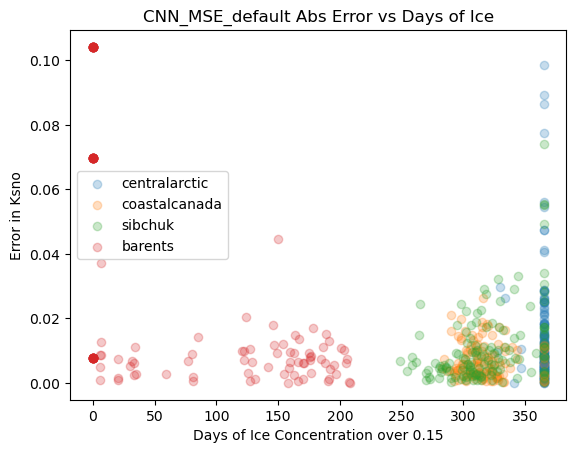

MAE in years with ice 0.0102
Percentage of error from years without ice: 43%


In [17]:
ice_days_year = torch.tensor(ice_days(val_index))
ice_mask = ice_days_year>0
years_with  = ice_mask.sum() 
years_without = (~ice_mask).sum()
for experiment, result in results.items():
    #print(experiment)
    error = torch.abs(result["guesses"] - truth_val)
    for loc in loc_list:
        mask = (loc_val ==loc)
        plt.scatter(ice_days_year[mask],error[mask], alpha=0.25, label=loc)
    plt.legend()
    plt.title(f"{experiment} Abs Error vs Days of Ice")
    plt.xlabel("Days of Ice Concentration over 0.15")
    plt.ylabel("Error in Ksno")
    plt.show()

    
    #print(f"{years_with} years with ice, {years_without} years without")
    print(f"MAE in years with ice {error[ice_mask].mean():.4f}")
    #print(f"MAE in years without ice {error[~ice_mask].mean():.4f}")
    print(f"Percentage of error from years without ice: {(error[~ice_mask].sum()/error.sum()):.0%}")
    #print(f"Percentage of years without ice: {years_without / (years_with + years_without):.0%}")

In [18]:
ice_table = [["Experiment", "MAE", "MAE adjusted", "Best Epoch"]]
for experiment, result in results.items():
    error = torch.abs(result["guesses"] - truth_val)
    mae = error.mean()
    mae_adj = error[ice_mask].mean()
    ice_table.append([experiment, round(float(mae),4), round(float(mae_adj),4), result["train_config"]["best_epoch"]])
    
#print(f"{years_with} years with ice, {years_without} years without")
print(f"Percentage of years without ice: {years_without / (years_with + years_without):.0%}")
print(tabulate(ice_table))



Percentage of years without ice: 11%
---------------  -----  ------------  ----------
Experiment       MAE    MAE adjusted  Best Epoch
CNN_MSE_default  0.016  0.0102        953
---------------  -----  ------------  ----------
